# Analisis Dataset Apple Inc. (AAPL) — SEC Financial Facts & Filings
**Tahapan:** Data Understanding → Pertanyaan Bisnis → Cleaning → Visualisasi Informasi → Visualisasi Strategis → Perbandingan → Insight & Rekomendasi

> ⚠️ **Catatan penting:** meskipun namanya "Apple Stocks", dataset ini **bukan data harga saham harian (OHLCV)**.
> Isinya adalah **laporan keuangan resmi dari SEC** (`financial_facts.csv`) dan **daftar dokumen yang dilaporkan ke SEC** (`filings.csv`).
> Jadi analisisnya berfokus pada **kinerja keuangan perusahaan**, bukan pergerakan harga saham.

## 1. Data Understanding

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

facts   = pd.read_csv('../financial_facts.csv')
filings = pd.read_csv('../filings.csv')
kamus   = pd.read_csv('../data_dictionary.csv')

print('financial_facts :', facts.shape)
print('filings         :', filings.shape)

financial_facts : (25135, 14)
filings         : (1002, 11)


### 1.1 Tabel profil tiap dataset (kolom, tipe data, missing value)

In [3]:
def profil(df):
    return pd.DataFrame({
        'tipe_data'   : df.dtypes.astype(str),
        'missing'     : df.isna().sum(),
        'missing_%'   : (df.isna().mean() * 100).round(1),
        'nilai_unik'  : df.nunique(),
    })

print('=== PROFIL: financial_facts ===')
display(profil(facts))
print('Baris duplikat:', facts.duplicated().sum())

=== PROFIL: financial_facts ===


,tipe_data,missing,missing_%,nilai_unik
taxonomy,str,0,0.0,2
concept,str,0,0.0,505
label,str,6,0.0,504
description,str,6,0.0,502
unit,str,0,0.0,6
value,float64,0,0.0,8758
accn,str,0,0.0,72
form,str,0,0.0,4
filed,str,0,0.0,69
fy,float64,569,2.3,18


Baris duplikat: 0


In [4]:
print('=== PROFIL: filings ===')
display(profil(filings))
print('Baris duplikat:', filings.duplicated().sum())

=== PROFIL: filings ===


,tipe_data,missing,missing_%,nilai_unik
accessionNumber,str,0,0.0,1002
filingDate,str,0,0.0,534
reportDate,str,222,22.2,405
form,str,0,0.0,34
primaryDocument,str,0,0.0,808
primaryDocDescription,str,93,9.3,44
items,str,899,89.7,11
size,int64,0,0.0,902
isXBRL,int64,0,0.0,2
isInlineXBRL,int64,0,0.0,2


Baris duplikat: 0


### 1.2 Rentang waktu & ringkasan dataset

In [5]:
facts['end']   = pd.to_datetime(facts['end'])
facts['filed'] = pd.to_datetime(facts['filed'])
filings['filingDate'] = pd.to_datetime(filings['filingDate'])

ringkasan = pd.DataFrame({
    'dataset'  : ['financial_facts', 'filings'],
    'baris'    : [len(facts), len(filings)],
    'kolom'    : [facts.shape[1], filings.shape[1]],
    'waktu_awal'  : [facts['end'].min().date(),  filings['filingDate'].min().date()],
    'waktu_akhir' : [facts['end'].max().date(),  filings['filingDate'].max().date()],
    'acuan_kolom_waktu': ['end (akhir periode laporan)', 'filingDate (tanggal lapor)'],
})
display(ringkasan)

print('Jenis form di financial_facts:')
print(facts['form'].value_counts().to_string())
print()
print('Satuan (unit):', facts['unit'].unique().tolist())

,dataset,baris,kolom,waktu_awal,waktu_akhir,acuan_kolom_waktu
0,financial_facts,25135,14,2006-09-30,2026-07-17,end (akhir periode laporan)
1,filings,1002,11,2015-09-18,2026-10-19,filingDate (tanggal lapor)


Jenis form di financial_facts:
form
10-Q      15304
10-K       8503
8-K        1118
10-K/A      210

Satuan (unit): ['shares', 'USD', 'USD/shares', 'pure', 'Year', 'Store']


**Temuan Data Understanding**
- `financial_facts` berisi puluhan ribu observasi angka laporan keuangan (satu baris = satu angka untuk satu periode & satu laporan).
- Satu periode bisa muncul **berkali-kali** (laporan kuartalan 10-Q, tahunan 10-K, dan perbaikan di tahun berikutnya) → **harus dibersihkan** supaya tidak terhitung ganda.
- Missing value besar ada di `start` dan `frame`, tapi itu **wajar** (data posisi neraca tidak punya tanggal mulai). Kolom `value` (angka utama) **tidak ada yang kosong**.
- `filings` berisi daftar dokumen yang dilaporkan Apple ke SEC. Kolom `items` banyak kosong karena hanya terisi untuk form 8-K.

## 2. Pertanyaan Bisnis

| Jenis | Pertanyaan | Kenapa masuk jenis ini |
|---|---|---|
| **Informasi** | *Bagaimana pertumbuhan pendapatan, laba bersih, dan margin laba Apple dari tahun ke tahun?* | Menjawab **"apa yang terjadi"** (deskriptif). Hanya melihat kondisi, belum ada keputusan yang diambil. |
| **Strategis** | *Dari kas operasi yang dihasilkan, berapa bagian yang dikembalikan ke pemegang saham (buyback + dividen), dan apakah porsi R&D & investasi (capex) cukup terjaga?* | Menjawab **"apa yang sebaiknya dilakukan"**. Hasilnya langsung dipakai untuk memutuskan alokasi dana: tambah buyback, atau perbesar R&D/investasi. |

## 3. Cleaning Data

Langkah cleaning yang dilakukan:
1. Ubah kolom tanggal ke tipe `datetime`.
2. Ambil hanya laporan **tahunan (10-K)** dengan durasi periode ±1 tahun dan satuan **USD**.
3. **Hapus duplikat:** jika satu periode dilaporkan lebih dari sekali, pakai versi **terbaru** (`filed` paling akhir).
4. Pilih konsep keuangan yang dibutuhkan, ubah jadi tabel per tahun (satu baris = satu tahun fiskal).
5. Gabungkan nama konsep pendapatan yang berubah seiring waktu (Apple mengganti tag XBRL-nya).
6. Hitung rasio turunan (margin, payout, dll).

In [6]:
facts['start'] = pd.to_datetime(facts['start'])
facts['durasi_hari'] = (facts['end'] - facts['start']).dt.days

# 2) Hanya laporan tahunan, durasi ~1 tahun, satuan USD
tahunan = facts[(facts['form'] == '10-K') &
                (facts['durasi_hari'].between(350, 380)) &
                (facts['unit'] == 'USD')].copy()

# 3) Hapus duplikat: ambil versi paling baru per (concept, end)
tahunan = tahunan.sort_values('filed').drop_duplicates(['concept', 'end'], keep='last')
tahunan['tahun'] = tahunan['end'].dt.year

# 4) Pilih konsep yang dibutuhkan
konsep = {
    'SalesRevenueNet'                                   : 'rev_lama',
    'Revenues'                                          : 'rev_mid',
    'RevenueFromContractWithCustomerExcludingAssessedTax': 'rev_baru',
    'GrossProfit'                                       : 'laba_kotor',
    'OperatingIncomeLoss'                               : 'laba_operasi',
    'NetIncomeLoss'                                     : 'laba_bersih',
    'ResearchAndDevelopmentExpense'                     : 'rnd',
    'NetCashProvidedByUsedInOperatingActivities'        : 'kas_operasi',
    'NetCashProvidedByUsedInOperatingActivitiesContinuingOperations': 'kas_operasi_alt',
    'PaymentsForRepurchaseOfCommonStock'                : 'buyback',
    'PaymentsOfDividends'                               : 'dividen',
    'PaymentsToAcquirePropertyPlantAndEquipment'        : 'capex',
}
df = (tahunan[tahunan['concept'].isin(konsep)]
      .pivot(index='tahun', columns='concept', values='value')
      .rename(columns=konsep))

# 5) Gabungkan nama konsep yang berbeda-beda
df['pendapatan'] = df['rev_baru'].fillna(df['rev_mid']).fillna(df['rev_lama'])
df['kas_operasi'] = df['kas_operasi'].fillna(df['kas_operasi_alt'])

# Ubah ke miliar USD
kolom = ['pendapatan', 'laba_kotor', 'laba_operasi', 'laba_bersih', 'rnd',
         'kas_operasi', 'buyback', 'dividen', 'capex']
df = df[kolom] / 1e9

# 6) Rasio turunan (dalam %)
df['margin_kotor_%']   = df['laba_kotor']  / df['pendapatan'] * 100
df['margin_bersih_%']  = df['laba_bersih'] / df['pendapatan'] * 100
df['pertumbuhan_pendapatan_%'] = df['pendapatan'].pct_change() * 100
df['rnd_%_pendapatan'] = df['rnd']   / df['pendapatan'] * 100
df['capex_%_pendapatan'] = df['capex'] / df['pendapatan'] * 100
df['kas_dikembalikan'] = df['buyback'] + df['dividen']
df['payout_%_kas_operasi'] = df['kas_dikembalikan'] / df['kas_operasi'] * 100

# Data siap pakai: 2013-2025 (buyback/dividen/capex baru lengkap sejak 2013)
data_siap = df.loc[2013:].round(2)

print('Missing value setelah cleaning:')
print(data_siap[kolom].isna().sum().to_string())
display(data_siap)

Missing value setelah cleaning:
concept
pendapatan      0
laba_kotor      0
laba_operasi    0
laba_bersih     0
rnd             0
kas_operasi     0
buyback         0
dividen         0
capex           0


concept,pendapatan,laba_kotor,laba_operasi,laba_bersih,rnd,kas_operasi,buyback,dividen,capex,margin_kotor_%,margin_bersih_%,pertumbuhan_pendapatan_%,rnd_%_pendapatan,capex_%_pendapatan,kas_dikembalikan,payout_%_kas_operasi
tahun,,,,,,,,,,,,,,,,
2013,170.91,64.30,49.00,37.04,4.47,53.67,22.86,10.53,8.16,37.62,21.67,9.20,2.62,4.78,33.39,62.21
2014,182.80,70.54,52.50,39.51,6.04,59.71,45.00,11.03,9.57,38.59,21.61,6.95,3.30,5.24,56.03,93.83
2015,233.72,93.63,71.23,53.39,8.07,81.27,35.25,11.56,11.25,40.06,22.85,27.86,3.45,4.81,46.81,57.61
2016,215.64,84.26,60.02,45.69,10.04,66.23,29.72,12.15,12.73,39.08,21.19,-7.73,4.66,5.91,41.87,63.22
2017,229.23,88.19,61.34,48.35,11.58,64.22,32.90,12.77,12.45,38.47,21.09,6.30,5.05,5.43,45.67,71.11
2018,265.60,101.84,70.90,59.53,14.24,77.43,72.74,13.71,13.31,38.34,22.41,15.86,5.36,5.01,86.45,111.64
2019,260.17,98.39,63.93,55.26,16.22,69.39,66.90,14.12,10.50,37.82,21.24,-2.04,6.23,4.03,81.02,116.75
2020,274.52,104.96,66.29,57.41,18.75,80.67,72.36,14.08,7.31,38.23,20.91,5.51,6.83,2.66,86.44,107.15
2021,365.82,152.84,108.95,94.68,21.91,104.04,85.97,14.47,11.08,41.78,25.88,33.26,5.99,3.03,100.44,96.54


In [7]:
data_siap.to_csv('apple_data_siap_pakai.csv')
print('Tersimpan: apple_data_siap_pakai.csv ->', data_siap.shape)

Tersimpan: apple_data_siap_pakai.csv -> (13, 16)


**Hasil cleaning:** data tahunan tiap tahun fiskal 2013–2025 (satuan miliar USD) tanpa missing value & tanpa duplikat.
Tahun 2007–2012 dibuang dari analisis utama karena data buyback, dividen, dan capex belum tersedia/lengkap di dataset.

## 4. Visualisasi untuk INFORMASI — *Apa yang terjadi?*

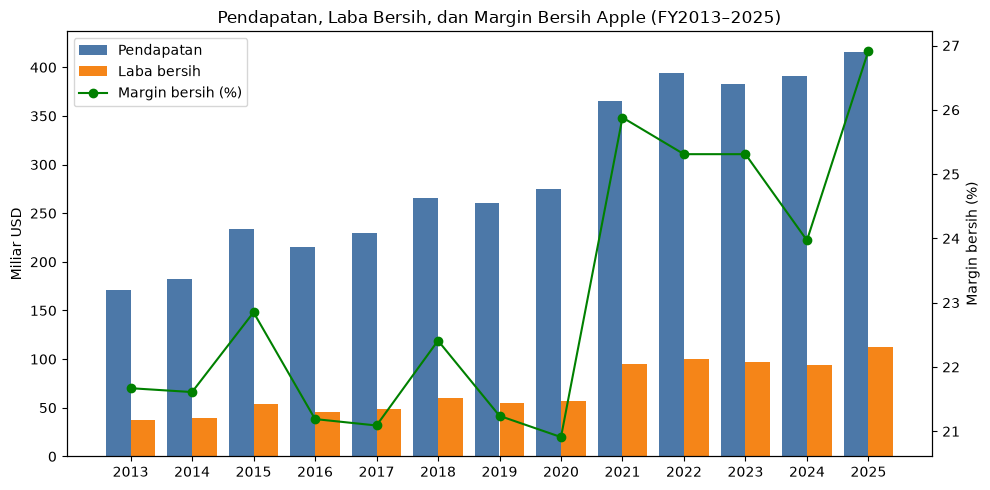

In [8]:
fig, ax1 = plt.subplots(figsize=(10, 5))
x = data_siap.index
ax1.bar(x - 0.2, data_siap['pendapatan'],  width=0.4, label='Pendapatan', color='#4C78A8')
ax1.bar(x + 0.2, data_siap['laba_bersih'], width=0.4, label='Laba bersih', color='#F58518')
ax1.set_ylabel('Miliar USD')
ax1.set_title('Pendapatan, Laba Bersih, dan Margin Bersih Apple (FY2013–2025)')

ax2 = ax1.twinx()
ax2.plot(x, data_siap['margin_bersih_%'], color='green', marker='o', label='Margin bersih (%)')
ax2.set_ylabel('Margin bersih (%)')

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper left')
plt.xticks(x, rotation=45)
plt.tight_layout()
plt.show()

In [9]:
awal, akhir = data_siap.index[0], data_siap.index[-1]
tahun_n = akhir - awal
cagr = ((data_siap.loc[akhir, 'pendapatan'] / data_siap.loc[awal, 'pendapatan']) ** (1 / tahun_n) - 1) * 100
print(f"Pendapatan {awal}: {data_siap.loc[awal,'pendapatan']:.0f} M  ->  {akhir}: {data_siap.loc[akhir,'pendapatan']:.0f} M")
print(f"Rata-rata pertumbuhan per tahun (CAGR): {cagr:.1f}%")
print(f"Margin bersih {awal}: {data_siap.loc[awal,'margin_bersih_%']:.1f}%  ->  {akhir}: {data_siap.loc[akhir,'margin_bersih_%']:.1f}%")
print('Tahun pendapatan turun:', data_siap.index[data_siap['pertumbuhan_pendapatan_%'] < 0].tolist())

Pendapatan 2013: 171 M  ->  2025: 416 M
Rata-rata pertumbuhan per tahun (CAGR): 7.7%
Margin bersih 2013: 21.7%  ->  2025: 26.9%
Tahun pendapatan turun: [2016, 2019, 2023]


**Kenapa ini kategori INFORMASI?** Chart ini hanya **menggambarkan kondisi** (pendapatan naik, laba naik, margin membaik). Belum ada pilihan tindakan yang bisa diambil dari chart ini saja.

## 5. Visualisasi untuk STRATEGIS — *Apa yang sebaiknya diputuskan?*

### 5.1 Ke mana kas operasi dialokasikan?

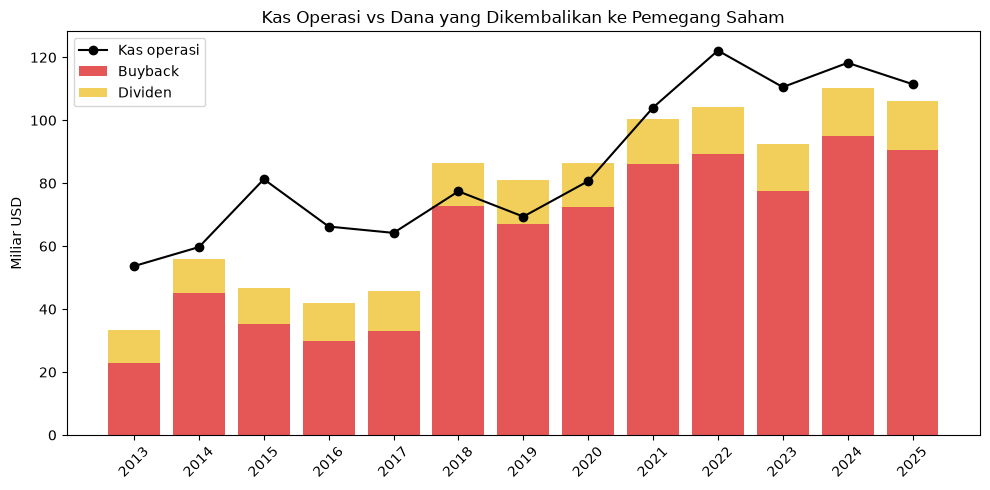

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
x = data_siap.index
ax.bar(x, data_siap['buyback'], label='Buyback', color='#E45756')
ax.bar(x, data_siap['dividen'], bottom=data_siap['buyback'], label='Dividen', color='#F2CF5B')
ax.plot(x, data_siap['kas_operasi'], color='black', marker='o', label='Kas operasi')
ax.set_ylabel('Miliar USD')
ax.set_title('Kas Operasi vs Dana yang Dikembalikan ke Pemegang Saham')
ax.legend(loc='upper left')
plt.xticks(x, rotation=45)
plt.tight_layout()
plt.show()

### 5.2 Apakah investasi masa depan (R&D & capex) terjaga?

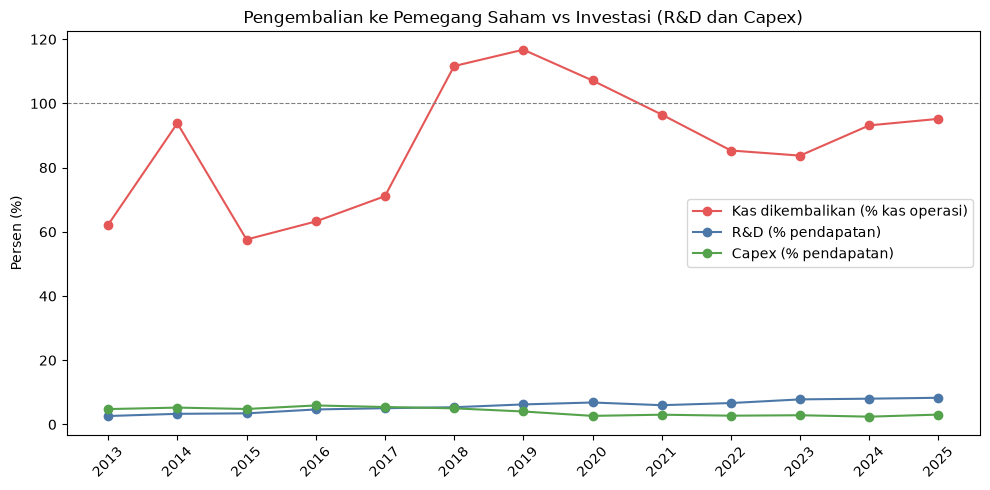

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(data_siap.index, data_siap['payout_%_kas_operasi'], marker='o', label='Kas dikembalikan (% kas operasi)', color='#E45756')
ax.plot(data_siap.index, data_siap['rnd_%_pendapatan'],     marker='o', label='R&D (% pendapatan)',   color='#4C78A8')
ax.plot(data_siap.index, data_siap['capex_%_pendapatan'],   marker='o', label='Capex (% pendapatan)', color='#54A24B')
ax.axhline(100, color='gray', linestyle='--', linewidth=0.8)
ax.set_ylabel('Persen (%)')
ax.set_title('Pengembalian ke Pemegang Saham vs Investasi (R&D dan Capex)')
ax.legend()
plt.xticks(data_siap.index, rotation=45)
plt.tight_layout()
plt.show()

**Kenapa ini kategori STRATEGIS?** Chart ini membandingkan **dua pilihan penggunaan dana** (dikembalikan ke pemegang saham vs diinvestasikan kembali) dan menunjukkan **rasio** yang bisa dipakai sebagai patokan keputusan, bukan sekadar menggambarkan angka.

## 6. Perbandingan antar periode

In [12]:
bandingan = data_siap.loc[[2013, 2017, 2021, 2025],
    ['pendapatan', 'laba_bersih', 'margin_bersih_%', 'rnd', 'rnd_%_pendapatan',
     'capex_%_pendapatan', 'kas_operasi', 'kas_dikembalikan', 'payout_%_kas_operasi']].T
bandingan.columns = [f'FY{c}' for c in bandingan.columns]
bandingan['Perubahan 2013→2025 (%)'] = ((bandingan['FY2025'] / bandingan['FY2013'] - 1) * 100).round(1)
display(bandingan.round(1))

,FY2013,FY2017,FY2021,FY2025,Perubahan 2013→2025 (%)
concept,,,,,
pendapatan,170.9,229.2,365.8,416.2,143.5
laba_bersih,37.0,48.4,94.7,112.0,202.4
margin_bersih_%,21.7,21.1,25.9,26.9,24.2
rnd,4.5,11.6,21.9,34.6,672.9
rnd_%_pendapatan,2.6,5.0,6.0,8.3,216.8
capex_%_pendapatan,4.8,5.4,3.0,3.1,-36.0
kas_operasi,53.7,64.2,104.0,111.5,107.7
kas_dikembalikan,33.4,45.7,100.4,106.1,217.8
payout_%_kas_operasi,62.2,71.1,96.5,95.2,53.0


## 7. Insight & Rekomendasi

In [13]:
r = data_siap
print('INSIGHT')
print(f"1. Pendapatan naik dari {r.loc[2013,'pendapatan']:.0f} M (FY2013) ke {r.loc[2025,'pendapatan']:.0f} M (FY2025), CAGR {cagr:.1f}%.")
print(f"2. Margin bersih naik dari {r.loc[2013,'margin_bersih_%']:.1f}% ke {r.loc[2025,'margin_bersih_%']:.1f}%.")
print(f"3. R&D naik dari {r.loc[2013,'rnd']:.1f} M ke {r.loc[2025,'rnd']:.1f} M ({r.loc[2013,'rnd_%_pendapatan']:.1f}% -> {r.loc[2025,'rnd_%_pendapatan']:.1f}% dari pendapatan).")
print(f"4. Rata-rata kas operasi yang dikembalikan ke pemegang saham 2021-2025: {r.loc[2021:2025,'payout_%_kas_operasi'].mean():.0f}%.")
print(f"5. Capex stabil di kisaran {r.loc[2021:2025,'capex_%_pendapatan'].min():.1f}-{r.loc[2021:2025,'capex_%_pendapatan'].max():.1f}% dari pendapatan (2021-2025).")

INSIGHT
1. Pendapatan naik dari 171 M (FY2013) ke 416 M (FY2025), CAGR 7.7%.
2. Margin bersih naik dari 21.7% ke 26.9%.
3. R&D naik dari 4.5 M ke 34.5 M (2.6% -> 8.3% dari pendapatan).
4. Rata-rata kas operasi yang dikembalikan ke pemegang saham 2021-2025: 91%.
5. Capex stabil di kisaran 2.4-3.1% dari pendapatan (2021-2025).


**Rekomendasi (berdasarkan data di atas):**
1. **Pertahankan kebijakan pengembalian kas**: selama porsi buyback+dividen berada di kisaran 85–95% kas operasi (2021–2025), kas masih cukup menopang pengembalian ini, namun ruang untuk menambah buyback lagi tipis.
2. **Jaga R&D tetap naik**: R&D tumbuh lebih cepat daripada pendapatan (rasio R&D/pendapatan naik), menunjukkan investasi produk terus diprioritaskan. Jangan dikorbankan demi buyback.
3. **Pantau capex**: capex turun dari sekitar 5% pendapatan (2013–2018) menjadi sekitar 3% (2021–2025). Jika perusahaan ingin ekspansi (misalnya AI/infrastruktur), porsi inilah yang perlu dinaikkan, bukan buyback.

**Batasan analisis:** dataset tidak memuat harga saham, sehingga tidak bisa menilai apakah buyback "murah" atau "mahal", dan tidak ada data segmen produk (iPhone, Services, dll) di analisis ini.

## 8. Mengapa informasi masuk "Informasi" atau "Strategis"?
| | Informasi | Strategis |
|---|---|---|
| Pertanyaan | Apa yang terjadi? | Apa yang harus diputuskan? |
| Contoh di sini | Tren pendapatan, laba, margin | Alokasi kas: buyback/dividen vs R&D/capex |
| Output | Gambaran kondisi | Rasio patokan + arah tindakan |
| Dipakai oleh | Semua pihak yang ingin tahu kondisi | Manajemen/investor yang mengambil keputusan |